# 04 — Đánh giá test với cấu hình và ngưỡng đã khóa

Notebook này chấm test, không train/tìm cấu hình hoặc chọn ngưỡng lại. Cần model local và kết quả validation đã tái tạo đúng phiên bản. Trước khi nạp test, kiểm tra config/code/model/split và tạo/kiểm tra evaluation-lock.json. Tái chạy là kiểm chứng kết quả cố định, không một test độc lập mới. Xem docs/TEST_EVALUATION.md.

In [1]:
from pathlib import Path
import sys
import pandas as pd
ROOT = Path.cwd().resolve()
while not (ROOT / "configs/evaluation.json").exists():
    if ROOT == ROOT.parent:
        raise RuntimeError("Mở notebook trong repository.")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
from maintenance.final_evaluation import run_final_evaluation
manifest = run_final_evaluation(ROOT)
assert manifest["refit"] is False and manifest["thresholds_from_validation"] is True
print("Đã chấm", manifest["runs_evaluated"], "run, không fit/chọn ngưỡng lại.")

Đã chấm 20 run, không fit/chọn ngưỡng lại.


In [2]:
table = pd.read_csv(ROOT / "reports/tables/test/primary-seed.csv")
display(table[["split_id", "model_family", "n_samples", "n_failures", "average_precision", "roc_auc", "tp_at_20", "tp_at_50", "tp_at_100", "precision_at_50", "recall_at_50", "tp", "fp", "fn", "tn", "precision", "recall", "f1"]])

,split_id,model_family,n_samples,n_failures,average_precision,roc_auc,tp_at_20,tp_at_50,tp_at_100,precision_at_50,recall_at_50,tp,fp,fn,tn,precision,recall,f1
0,ordered-gap100-v1,isolation_forest,1900,38,0.181338,0.853101,8.0,13.0,15.0,0.26,0.342105,13,25,25,1837,0.342105,0.342105,0.342105
1,ordered-gap100-v1,random,1900,38,0.021138,0.484086,0.0,0.0,1.0,0.00,0.000000,32,1762,6,100,0.017837,0.842105,0.034934
2,ordered-gap100-v1,always_normal,1900,38,0.020000,0.500000,NaN,NaN,NaN,NaN,NaN,0,0,38,1862,NaN,0.000000,0.000000
3,ordered-gap100-v1,logistic_regression,1900,38,0.536754,0.867870,15.0,21.0,25.0,0.42,0.552632,10,1,28,1861,0.909091,0.263158,0.408163
4,stratified-seed42-v1,isolation_forest,2000,68,0.173645,0.836545,6.0,11.0,17.0,0.22,0.161765,11,43,57,1889,0.203704,0.161765,0.180328
5,stratified-seed42-v1,random,2000,68,0.028758,0.439548,0.0,0.0,0.0,0.00,0.000000,13,560,55,1372,0.022688,0.191176,0.040562
6,stratified-seed42-v1,always_normal,2000,68,0.034000,0.500000,NaN,NaN,NaN,NaN,NaN,0,0,68,1932,NaN,0.000000,0.000000
7,stratified-seed42-v1,logistic_regression,2000,68,0.452184,0.923517,11.0,27.0,43.0,0.54,0.397059,25,16,43,1916,0.609756,0.367647,0.458716


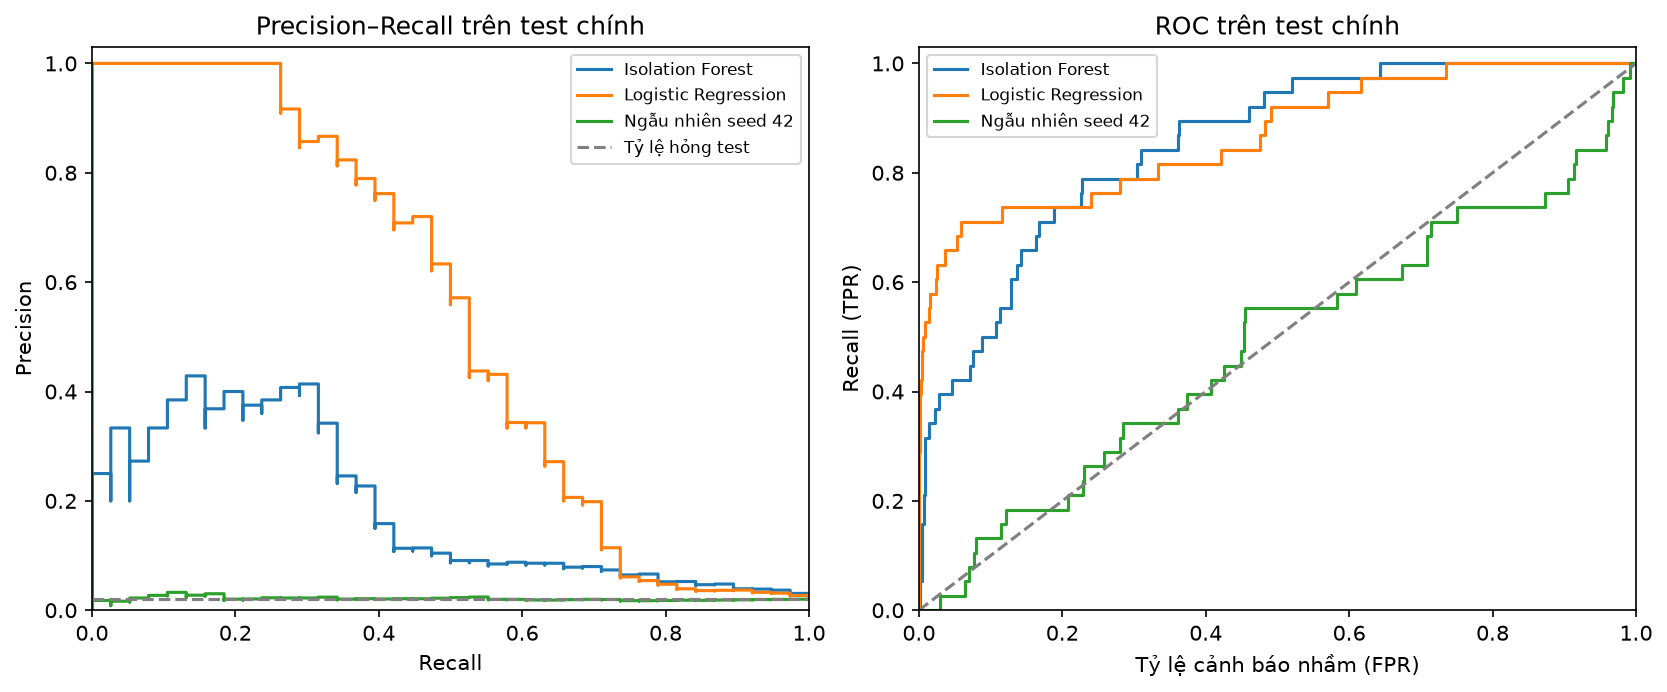

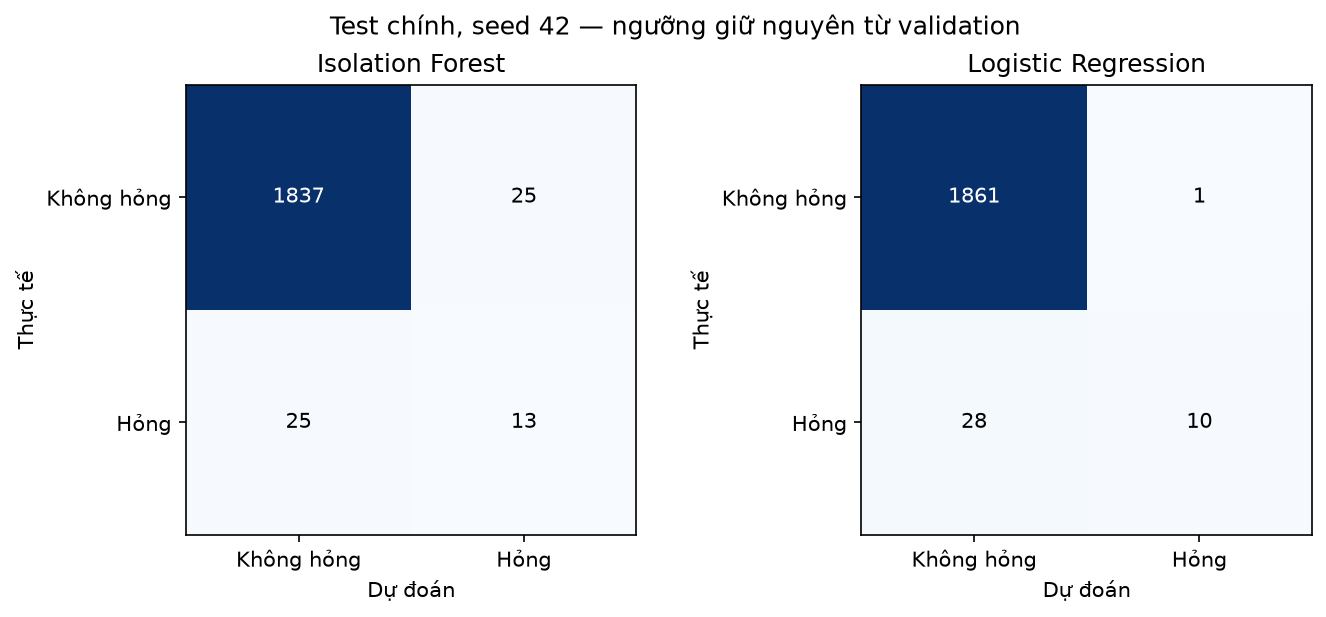

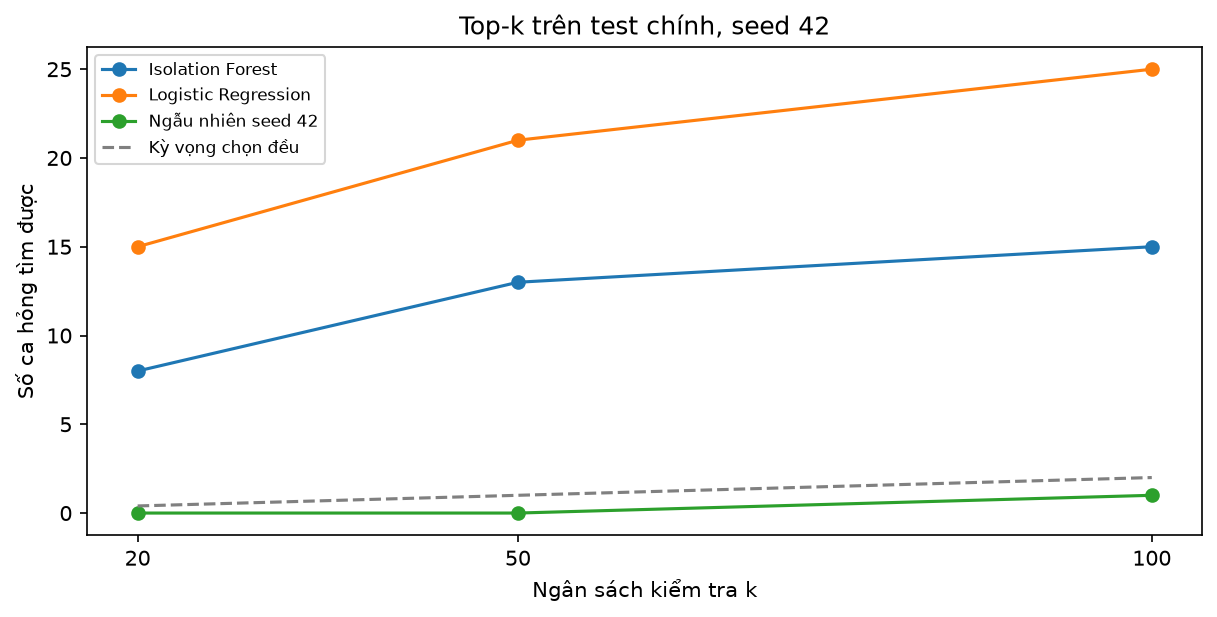

,model_family,metric,lower_percentile_2_5,upper_percentile_97_5,valid_resamples,requested_resamples,block_rows,interpretation
0,isolation_forest,average_precision,0.127505,0.294669,500,500,100,exploratory block bootstrap; independence/cove...
1,isolation_forest,roc_auc,0.805388,0.895140,500,500,100,exploratory block bootstrap; independence/cove...
2,logistic_regression,average_precision,0.384615,0.683990,500,500,100,exploratory block bootstrap; independence/cove...
3,logistic_regression,roc_auc,0.789613,0.931558,500,500,100,exploratory block bootstrap; independence/cove...
4,LR_minus_IF,average_precision_difference,0.162631,0.495506,500,500,100,exploratory block bootstrap; independence/cove...


In [3]:
from IPython.display import Image, display
for name in ["01-curves.png", "02-confusion.png", "03-budgets.png"]:
    display(Image(filename=str(ROOT / "reports/figures/test" / name)))
display(pd.read_csv(ROOT / "reports/tables/test/bootstrap.csv"))

## Sai sót và giới hạn

Top-k và ngưỡng là hai chính sách riêng. Không đổi threshold để giảm bỏ sót sau khi đã thấy test. Phân tích Type/mode là hậu kiểm, không đưa nhãn vào tạo danh sách ưu tiên; mode có thể chồng lấp. Nhóm không có ca hỏng không xác định được recall. Bootstrap khối 100 dòng chỉ thăm dò độ dao động, chưa bảo đảm độc lập/coverage, không khẳng định kiểm định ý nghĩa thống kê. Seed thuật toán và resampling không tạo nhiều tập dữ liệu độc lập.

Sau test, giữ cấu hình v1 cho báo cáo. Nếu phát triển cải tiến từ lỗi test đã xem, cần thiết kế đánh giá mới; không tự gọi điểm trên test cũ là kết quả độc lập của cải tiến.

In [4]:
groups = pd.read_csv(ROOT / "reports/tables/test/groups.csv")
display(groups.loc[groups.split_id.eq("ordered-gap100-v1") & groups.seed.eq(42) & groups.model_family.eq("logistic_regression"), ["group", "rows", "n_failures", "tp", "fp", "fn", "global_top50_hits", "global_top50_recall"]])
print("Điểm và lỗi cấp bản ghi giữ local; bảng/hình tổng hợp dùng chung cho kho, dashboard và báo cáo.")

,group,rows,n_failures,tp,fp,fn,global_top50_hits,global_top50_recall
72,Type=L,1117,31,6,1,25,15,0.483871
73,Type=M,573,7,4,0,3,6,0.857143
74,Type=H,210,0,0,0,0,0,NaN
75,mode=twf,10,10,0,0,10,1,0.100000
76,mode=hdf,0,0,0,0,0,0,NaN
77,mode=pwf,10,10,6,0,4,8,0.800000
78,mode=osf,20,20,7,0,13,16,0.800000
79,mode=rnf,0,0,0,0,0,0,NaN


Điểm và lỗi cấp bản ghi giữ local; bảng/hình tổng hợp dùng chung cho kho, dashboard và báo cáo.
